# Source models in field tracing: partial coherence, spectra and pulses

A field tracing chain (notebook 109, field tracing) carries one harmonic field: one
wavelength, perfectly coherent across the beam. Real sources are neither.
A multimode laser, an LED or a lamp is only partially coherent in space,
and every real source has a spectrum, from the few gigahertz of a
single-frequency laser to the hundred terahertz of a femtosecond pulse.

Field tracing handles these sources without changing the chain: the source
is decomposed into **modes**, harmonic fields that are traced one by one,
and the results are added at the detector with the right statistics. This
is the approach of the commercial field tracing software VirtualLab Fusion
(Wyrowski and Kuhn 2011), and `pyoptics.source_modes` implements it on top
of `pyoptics.fieldtrace`:

- Modes that are **mutually incoherent** (the coherent modes of a partially
  coherent beam, the emitters of an extended source, the wavelengths of a
  stationary broadband source) add in irradiance:
  $I(\mathbf r) = \sum_j w_j |E_j(\mathbf r)|^2$. The correlations between
  two points, the mutual intensity
  $J(\mathbf r_1, \mathbf r_2) = \sum_j w_j\, E_j(\mathbf r_1)\cdot E_j^*(\mathbf r_2)$,
  add in the same way.
- The frequencies of a **pulse** are mutually coherent: the spectral fields
  add with their complex amplitudes, $E(\mathbf r, t) = \sum_j a_j
  E_j(\mathbf r)\, e^{-i\omega_j t}$.

The notebook works through four sources:

1. a Gaussian Schell model beam, the standard model of a partially coherent
   laser beam, and its coherent modes,
2. a multimode laser focused into a single-mode fibre,
3. an extended incoherent source (an LED) and the van Cittert–Zernike
   theorem, with and without a collimator,
4. broadband light in Young's double slit, and a 20 fs pulse focused by an
   aspheric singlet, where the pulse front lags behind the phase front
   (Bor's effect).

Related notebooks: 07 (beam quality) for $M^2$, 74 (coherence and stellar
interferometry) for coherence functions, 81 (ultrashort pulses) for Bor's
effect from rays, and 112 (field tracing applications) for fibre coupling
with a coherent beam.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

from pyoptics import fieldtrace as ft
from pyoptics import source_modes as sm
from pyoptics import glasses
from pyoptics import ultrafast as uf
from pyoptics.raytrace import System, Surface

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()

## 1. The Gaussian Schell model and its coherent modes

The Gaussian Schell model (GSM) describes a beam whose irradiance and
whose coherence both fall off as Gaussians. In one dimension its cross
spectral density, the correlation of the field at two points $x_1$ and
$x_2$, is

$$W(x_1, x_2) = \exp\!\left(-\frac{x_1^2 + x_2^2}{4\sigma_s^2}\right)
\exp\!\left(-\frac{(x_1 - x_2)^2}{2\sigma_g^2}\right),$$

with the rms width $\sigma_s$ of the irradiance and the rms coherence width
$\sigma_g$. Like any cross spectral density it has a **coherent mode
representation** (Mandel and Wolf, section 4.7): it is a sum of
mutually incoherent, fully coherent modes,

$$W(x_1, x_2) = \sum_n \lambda_n\, \phi_n(x_1)\, \phi_n^*(x_2).$$

For the GSM the modes are the Hermite–Gaussian beams of one waist $w_0$
and the weights fall off geometrically, $\lambda_n \propto \kappa^n$
(Gori 1983, Starikov and Wolf 1982). A fully coherent beam
($\sigma_g \to \infty$) has $\kappa = 0$ and a single mode; the less
coherent the beam, the closer $\kappa$ comes to 1 and the more modes it
takes. The beam quality is $M^2 = \sqrt{1 + 4\sigma_s^2/\sigma_g^2} =
(1 + \kappa)/(1 - \kappa)$.

`sm.gaussian_schell()` builds the ensemble of modes, keeping the strongest
modes that carry 99.9 % of the power:

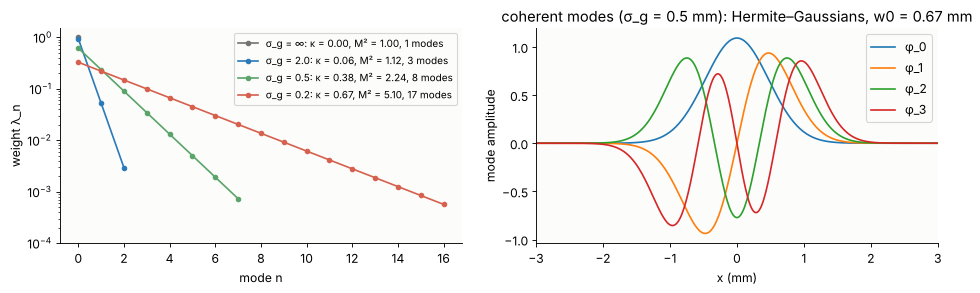

In [2]:
wl = 1.0e-3                     # 1 µm, lengths in mm
sigma_s = 0.5                   # rms width of the irradiance
x = np.linspace(-8, 8, 1024)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for sg, c in zip([np.inf, 2.0, 0.5, 0.2], [GREY, BLUE, GREEN, RED]):
    ens = sm.gaussian_schell(sigma_s, sg, wl, x)
    k = ens.info["kappa"][0]
    lab = "σ_g = {}: κ = {:.2f}, M² = {:.2f}, {} modes".format(
        "∞" if np.isinf(sg) else sg, k, ens.info["M2"][0], len(ens))
    ax[0].semilogy(np.arange(len(ens)), ens.weights, "o-", color=c, ms=4, label=lab)
ax[0].set_xlabel("mode n"); ax[0].set_ylabel("weight λ_n"); ax[0].set_ylim(1e-4, 1.5)
ax[0].legend(fontsize=9)
ens = sm.gaussian_schell(sigma_s, 0.5, wl, x)
for n in range(4):
    ax[1].plot(x, ens.fields[n].scalar_amplitude.real, label="φ_{}".format(n))
ax[1].set_xlim(-3, 3); ax[1].set_xlabel("x (mm)"); ax[1].set_ylabel("mode amplitude")
ax[1].set_title("coherent modes (σ_g = 0.5 mm): Hermite–Gaussians, w0 = {:.2f} mm".format(ens.info["w0"]))
ax[1].legend()
plt.tight_layout(); plt.show()

### Propagation: every mode diffracts on its own

Each mode is an ordinary Hermite–Gaussian beam that the chain propagates
with the automatically chosen operator; the ensemble result adds the
irradiances. The GSM beam stays Gaussian and spreads like a Gaussian beam
whose Rayleigh length is shorter by the factor $M^2$:
$\sigma(z)^2 = \sigma_s^2\,[1 + (z M^2/(2k\sigma_s^2))^2]$
(`sm.gsm_width()`). The traced widths follow the formula:

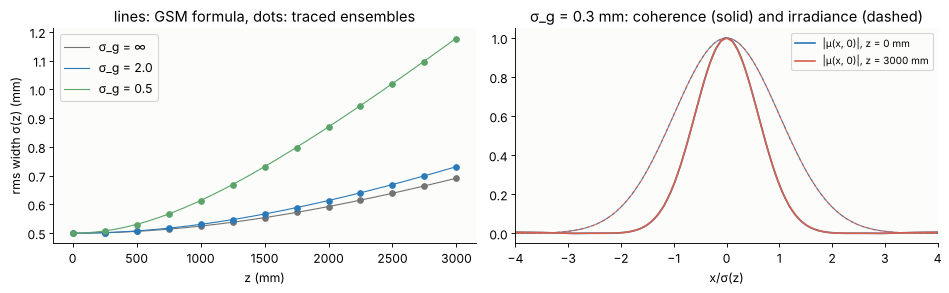

In [3]:
zs = np.linspace(0, 3000, 13)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for sg, c in zip([np.inf, 2.0, 0.5], [GREY, BLUE, GREEN]):
    ens = sm.gaussian_schell(sigma_s, sg, wl, x)
    widths = []
    for z in zs:
        res = sm.trace([ft.Propagate(z, method="spw"), ft.Detector("d")], ens) if z else \
            sm.trace([ft.Detector("d")], ens)
        xx, _ = res.grid("d")
        I = res.irradiance("d", xx)
        widths.append(np.sqrt(np.sum(I*xx**2)/np.sum(I)))
    zz = np.linspace(0, 3000, 200)
    ax[0].plot(zz, sm.gsm_width(sigma_s, sg, zz, wl), color=c, lw=1,
               label="σ_g = {}".format("∞" if np.isinf(sg) else sg))
    ax[0].plot(zs, widths, "o", color=c, ms=5)
ax[0].set_xlabel("z (mm)"); ax[0].set_ylabel("rms width σ(z) (mm)")
ax[0].set_title("lines: GSM formula, dots: traced ensembles"); ax[0].legend()

# degree of coherence relative to the beam centre, at the source and after 3 m,
# for a beam with sigma_g = 0.3 mm
ens = sm.gaussian_schell(sigma_s, 0.3, wl, x)
for z, c in [(0.0, BLUE), (3000.0, RED)]:
    res = sm.trace(([ft.Propagate(z, method="spw")] if z else []) + [ft.Detector("d")], ens)
    xx, _ = res.grid("d")
    s = sm.gsm_width(sigma_s, 0.3, z, wl)
    mu = res.degree_of_coherence("d", 0.0, xx)
    I = res.irradiance("d", xx)
    ax[1].plot(xx/s, I/I.max(), "--", color=c, lw=1)
    ax[1].plot(xx/s, np.abs(mu), color=c, label="|μ(x, 0)|, z = {:.0f} mm".format(z))
ax[1].set_xlim(-4, 4); ax[1].set_xlabel("x/σ(z)")
ax[1].set_title("σ_g = 0.3 mm: coherence (solid) and irradiance (dashed)")
ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

On the right, for a beam with $\sigma_g = 0.3$ mm, the degree of coherence
$|\mu(x, 0)|$ between a point $x$ and the beam centre: at the source it is
the Gaussian $\exp(-x^2/2\sigma_g^2)$, narrower than the beam, and after
three metres it has grown with the beam. In units of the beam width both curves coincide: the GSM beam is
*shape invariant*, its coherence width and its width grow in proportion.
The ratio $\sigma_g/\sigma_s$, and with it the number of modes and $M^2$, is
a property of the beam that free space cannot change.

## 2. A multimode laser focused into a single-mode fibre

A real multimode laser is often modelled the same way: an incoherent
mixture of Hermite–Gaussian modes. With a thermal (geometric)
distribution of the mode powers, $p_n \propto \kappa^n$ with $\kappa =
(M^2-1)/(M^2+1)$, the mixture has exactly the beam quality $M^2$, and it
*is* the Gaussian Schell model beam. `sm.multimode_laser(W, M2, ...)`
takes the second-moment radius $W$ and $M^2$ (different in $x$ and $y$ if
needed) or an explicit list of modes.

Notebook 112 (field tracing applications) focused a coherent Gaussian beam
into a single-mode fibre. Here a 1 mm laser beam with $M^2$ between 1 and 3
is focused by an ideal lens of 20 mm focal length onto a fibre with a mode
field radius of 5 µm. A `Detector` with the `"coupling"` quantity computes
the overlap with the fibre mode for every laser mode, and the ensemble
result adds the coupled powers.

14 modes traced in 2.8 s, coupled: 0.441


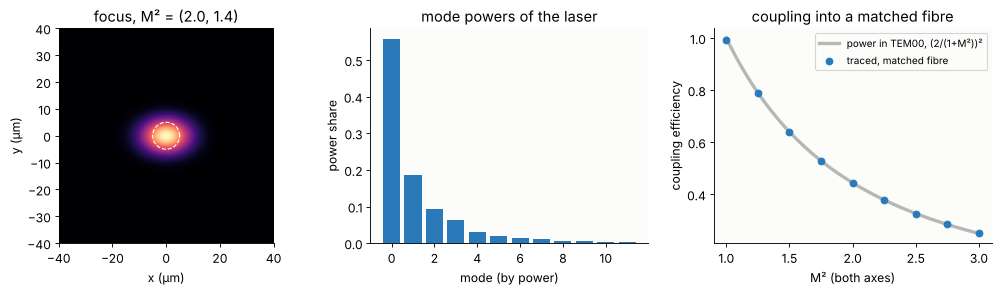

In [4]:
f_lens, w_fibre = 20.0, 5.0e-3
W = 1.0                                         # second-moment radius on the lens
xs = np.linspace(-4, 4, 192)
xf = np.linspace(-0.04, 0.04, 161)
fibre = ft.gaussian(w_fibre, wl, xf, xf)
chain = [ft.ThinLens(f_lens), ft.Propagate(f_lens), ft.Detector("fibre", ("irradiance", "coupling"),
                                                                    x=xf, y=xf, mode=fibre)]
t0 = time.time()
laser = sm.multimode_laser(W, (2.0, 1.4), wl, xs, xs, fraction=0.995)
res = sm.trace(chain, laser)
I = res.irradiance("fibre", xf, xf)
print("{} modes traced in {:.1f} s, coupled: {:.3f}".format(len(laser), time.time() - t0,
                                                            res.coupling("fibre")))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
im = ax[0].imshow(I/I.max(), extent=1e3*np.array([xf[0], xf[-1], xf[0], xf[-1]]), origin="lower",
                  cmap="magma")
ax[0].set_title("focus, M² = (2.0, 1.4)"); ax[0].set_xlabel("x (µm)"); ax[0].set_ylabel("y (µm)")
th = np.linspace(0, 2*np.pi, 100)
ax[0].plot(1e3*w_fibre*np.cos(th), 1e3*w_fibre*np.sin(th), "w--", lw=1)
ax[1].bar(range(12), sorted(laser.weights)[::-1][:12], color=BLUE)
ax[1].set_xlabel("mode (by power)"); ax[1].set_ylabel("power share")
ax[1].set_title("mode powers of the laser")

# coupling versus M² into the best fibre for each laser: the fibre mode matched to the
# focused embedded Gaussian (1D cuts: the coupling into a round mode factorizes)
x1 = np.linspace(-4, 4, 512)
M2s = np.linspace(1, 3, 9)
eta = []
for M2 in M2s:
    w_match = wl*f_lens*np.sqrt(M2)/(np.pi*W)
    chain1 = [ft.ThinLens(f_lens), ft.Propagate(f_lens),
              ft.Detector("fibre", ("coupling",), x=xf, mode=ft.gaussian(w_match, wl, xf))]
    ens = sm.multimode_laser(W, M2, wl, x1, fraction=0.9999)
    eta.append(sm.trace(chain1, ens).coupling("fibre")**2)
mm = np.linspace(1, 3, 100)
ax[2].plot(mm, (2/(1 + mm))**2, color=GREY, lw=3, alpha=0.5, label="power in TEM00, (2/(1+M²))²")
ax[2].plot(M2s, eta, "o", color=BLUE, ms=6, label="traced, matched fibre")
ax[2].set_xlabel("M² (both axes)"); ax[2].set_ylabel("coupling efficiency")
ax[2].set_title("coupling into a matched fibre"); ax[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

On the left, a laser with $M^2 = 2$ in $x$ and 1.4 in $y$ is focused onto a
fibre with a 5 µm mode field radius (dashed circle); 44 % of its power is
coupled. On the right, for each $M^2$ the fibre is matched to the focused
*embedded Gaussian*, the fundamental mode $w_0 = W/\sqrt{M^2}$ of the
laser, the best a single-mode fibre can do. The traced coupling is exactly
the power share of that mode, $(1-\kappa)^2 = (2/(1+M^2))^2$ for both
axes: the higher order modes are orthogonal to a Gaussian fibre mode and
are lost, whatever the lens does. A laser with $M^2 = 2$ couples less than
half its power into a single-mode fibre: the beam quality, not the
optics, sets the limit.

## 3. An extended incoherent source: the van Cittert–Zernike theorem

An LED, a lamp or a star consists of a huge number of independent
emitters. `sm.lambertian_disk()` samples a disk (or, in one dimension, a
strip) with point emitters on a sunflower spiral, each one radiating a
spherical wave (`sm.point_source()`, with the exact phase $k r$ and the
paraxial part kept analytic). The emitters are mutually incoherent.

The van Cittert–Zernike theorem predicts the coherence that such a source
produces far away: the degree of coherence between two points is the
Fourier transform of the source's irradiance. For a uniform strip of half
width $a$ at distance $d$, $\mu(\Delta x) = \sin(u)/u$ with $u = k a
\Delta x/d$; for a disk, $2 J_1(u)/u$. Light from a 1 mm LED die is
spatially coherent over only about 20 µm at a distance of 20 mm, and over
a millimetre at a metre (for stars, compare
notebook 74, coherence and stellar interferometry).

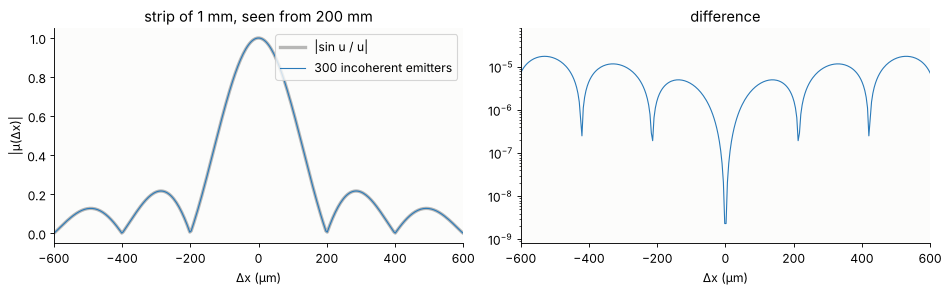

In [5]:
a_s, d = 0.5, 200.0
xs = np.linspace(-1.5, 1.5, 768)
strip = sm.lambertian_disk(a_s, d, wl, xs, None, n_points=300, m=0)
res = sm.trace([ft.Detector("d")], strip)
mu = res.degree_of_coherence("d", 0.0, xs)
u = 2*np.pi/wl*a_s*xs/d

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(xs*1e3, np.abs(np.sinc(u/np.pi)), color=GREY, lw=3, alpha=0.5, label="|sin u / u|")
ax[0].plot(xs*1e3, np.abs(mu), color=BLUE, lw=1, label="300 incoherent emitters")
ax[0].set_xlim(-600, 600); ax[0].set_xlabel("Δx (µm)"); ax[0].set_ylabel("|μ(Δx)|")
ax[0].set_title("strip of 1 mm, seen from 200 mm"); ax[0].legend()
ax[1].semilogy(xs*1e3, np.abs(np.abs(mu) - np.abs(np.sinc(u/np.pi))) + 1e-12, color=BLUE, lw=1)
ax[1].set_xlim(-600, 600); ax[1].set_xlabel("Δx (µm)"); ax[1].set_title("difference")
plt.tight_layout(); plt.show()

### An LED behind a collimator

Put a lens of focal length $f$ one focal length in front of the LED, as in a
flashlight or a Köhler condenser
(notebook 85, Köhler and critical illumination). Each emitter becomes a plane wave tilted by its position
over $f$, the collimated beam diverges by the angular size of the die,
and the van Cittert–Zernike theorem applies directly behind the lens, with
$d$ replaced by $f$: the coherence width is set by the source size and the
focal length, not by the size of the beam. Below, a 0.4 mm LED die with a
Lambertian emission pattern behind an ideal thin lens with $f = 20$ mm and
an aperture of 2 mm radius, and the beam on a screen 500 mm further on.
(The thin lens has a purely quadratic phase; at this numerical aperture of
0.1 it leaves a quarter of a wave of spherical aberration on the exact
spherical waves of the emitters.)

120 emitters in 8.2 s


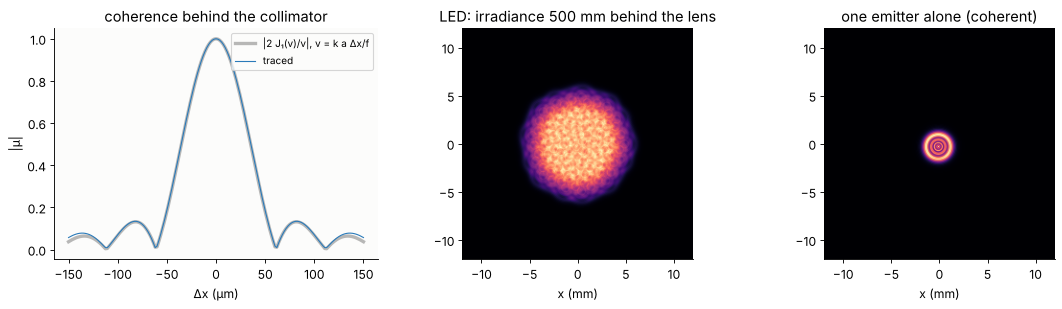

divergence of the LED beam: ±a/f = ±10 mrad, i.e. ±5 mm at 500 mm, plus the beam radius of 2 mm


In [6]:
a_led, f_c, r_lens = 0.2, 20.0, 2.0
xl = np.linspace(-2.5, 2.5, 200)
xscr = np.linspace(-12, 12, 241)                 # screen grid
t0 = time.time()
led = sm.lambertian_disk(a_led, f_c, wl, xl, xl, n_points=120, m=1.0, na=0.2)
# lens aperture of 2 mm radius with a slightly smoothed edge; Fresnel propagation
# to the screen (a hard edge 500 mm away would ask the rigorous operator for
# millions of samples)
aperture = lambda X, Y: 0.5*(1 - np.tanh((np.hypot(X, Y) - r_lens)/0.03))
chain = [ft.Aperture(mask=aperture), ft.ThinLens(f_c), ft.Detector("behind lens", x=xl, y=xl),
         ft.Propagate(500.0, method="fresnel"), ft.Detector("screen", x=xscr, y=xscr)]
res = sm.trace(chain, led)
print("{} emitters in {:.1f} s".format(len(led), time.time() - t0))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
dx = np.linspace(-0.15, 0.15, 161)
mu = res.degree_of_coherence("behind lens", (0.0, 0.0), dx, np.array([0.0, 1e-9]))[0]
v = 2*np.pi/wl*a_led*dx/f_c
jinc = np.where(np.abs(v) < 1e-9, 1.0, 2*j1(v)/np.where(np.abs(v) < 1e-9, 1, v))
ax[0].plot(dx*1e3, np.abs(jinc), color=GREY, lw=3, alpha=0.5, label="|2 J₁(v)/v|, v = k a Δx/f")
ax[0].plot(dx*1e3, np.abs(mu), color=BLUE, lw=1, label="traced")
ax[0].set_xlabel("Δx (µm)"); ax[0].set_ylabel("|μ|"); ax[0].legend(fontsize=9)
ax[0].set_title("coherence behind the collimator")

xs_, ys_ = xscr, xscr
I = res.irradiance("screen", xs_, ys_)
ext = [xs_[0], xs_[-1], ys_[0], ys_[-1]]
ax[1].imshow(I/I.max(), extent=ext, origin="lower", cmap="magma")
ax[1].set_title("LED: irradiance 500 mm behind the lens"); ax[1].set_xlabel("x (mm)")
one = sm.trace(chain, sm.coherent(led.fields[0]))
I1 = one.irradiance("screen", xs_, ys_)
ax[2].imshow(I1/I1.max(), extent=ext, origin="lower", cmap="magma")
ax[2].set_title("one emitter alone (coherent)"); ax[2].set_xlabel("x (mm)")
plt.tight_layout(); plt.show()
print("divergence of the LED beam: ±a/f = ±{:.0f} mrad, i.e. ±{:.0f} mm at 500 mm, plus the "
      "beam radius of {:.0f} mm".format(1e3*a_led/f_c, 500*a_led/f_c, r_lens))

A single emitter gives a sharply bounded collimated beam with diffraction
ripples from the lens aperture. The LED fills the sum of all the tilted
copies: the irradiance on the screen is the image of the die convolved
with the aperture, and the ripples are gone. The faint grain that is
left marks the 120 sampled emitters; more emitters smooth it out. This is
the field tracing view of why incoherent illumination looks smooth.

## 4. Spectra and pulses

### Broadband light in Young's double slit

A stationary broadband source is an incoherent ensemble over wavelengths
(`sm.polychromatic()`, with weights from `sm.gaussian_spectrum()`). Every
wavelength makes its own fringe pattern, with a period proportional to the
wavelength; the patterns agree at the centre and drift apart further out,
where the path difference between the two slits approaches the coherence
length $\ell_c \approx \lambda^2/\Delta\lambda$. The visibility follows
the degree of temporal coherence of the source
(notebook 74, coherence and stellar interferometry), for a Gaussian spectrum
$|\gamma(\tau)| = \exp[-(\pi\,\Delta\nu\,\tau)^2/(4\ln 2)]$ with the
delay $\tau = \mathrm{OPD}/c$.

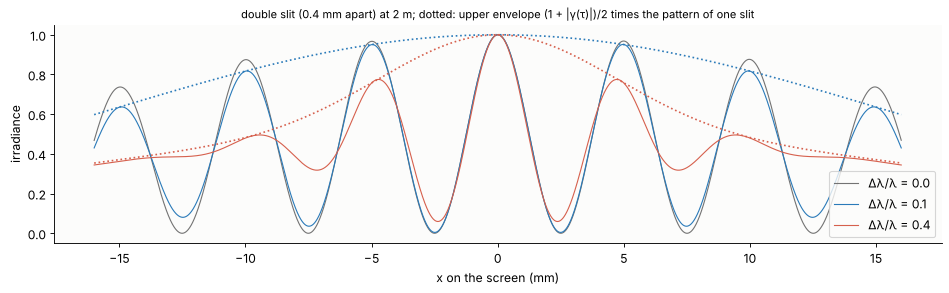

In [7]:
xg = np.linspace(-1, 1, 2048)
slits = lambda u: ((np.abs(u - 0.2) < 0.02) | (np.abs(u + 0.2) < 0.02)).astype(float)
L_screen = 2000.0
xd = np.linspace(-16, 16, 6401)
chain = [ft.Aperture(mask=slits), ft.Propagate(L_screen, method="fresnel_ft"),
         ft.Detector("screen", x=xd)]
make = lambda w: ft.Field(np.ones_like(xg), xg, None, w)

fig, ax = plt.subplots(1, 1, figsize=(12, 3.8))
for frac, c in [(0.0, GREY), (0.1, BLUE), (0.4, RED)]:
    if frac == 0:
        ens = sm.coherent(make(wl))
    else:
        wls, wts = sm.gaussian_spectrum(wl, frac*wl, n=31)
        ens = sm.polychromatic(make, wls, wts)
    I = sm.trace(chain, ens).irradiance("screen", xd)
    ax.plot(xd, I/I.max(), color=c, lw=1, label="Δλ/λ = {}".format(frac))
    if frac > 0:
        opd = 0.4*xd/L_screen                         # slit separation 0.4 mm
        dnu = frac/wl                                 # in 1/mm
        env = np.exp(-(np.pi*dnu*opd)**2/(4*np.log(2)))
        slit = np.sinc(0.04*xd/(wl*L_screen))**2      # one slit of 40 µm
        ax.plot(xd, 0.5*(1 + env)*slit, ":", color=c, lw=1.5)
ax.set_xlabel("x on the screen (mm)"); ax.set_ylabel("irradiance")
ax.set_title("double slit (0.4 mm apart) at 2 m; dotted: upper envelope (1 + |γ(τ)|)/2 "
             "times the pattern of one slit", fontsize=10)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### A 20 fs pulse focused by a singlet: Bor's effect

The frequencies of a pulse are mutually *coherent*. `sm.gaussian_pulse()`
samples its spectrum at equidistant frequencies, each with a complex
amplitude that may carry a spectral phase (here a negative group delay
dispersion, GDD, that pre-compensates the glass on the axis of the lens,
as a prism compressor would). The chain is a callable that builds the lens
for each wavelength, `lens.with_wavelength(wl)`, so that the glass
disperses: rays through the lens, wave optics into the focus
(`ft.Chain.from_system()`).

The lens is a plano-convex singlet of N-BK7 whose convex side is a
hyperboloid, so the phase front at the focus is perfect at the centre
wavelength. The pulse front is not: the group velocity in glass is lower
than the phase velocity, and the pulse that crosses the thick centre of
the lens lags behind the pulse at the thin rim by Bor's delay,
$\Delta T(r) = -\frac{r^2}{2c}\,\lambda\,\frac{dP}{d\lambda}$ (notebook 81,
ultrashort pulses). In the focus the contributions of all pupil zones
arrive spread over $\Delta T(a)$, and the focal pulse is longer than the
input pulse: the model of Bor and Horváth predicts the axial pulse
(`uf.bor_axis_spectrum()`).

In [8]:
bk7 = glasses.get("N-BK7")
wl0, f_l, a_l, T_l = 800e-6, 50.0, 6.0, 4.0
n0 = bk7.n(800.0)
lens = System([Surface(thickness=T_l, material=bk7, semi_diameter=a_l + 0.5),
               Surface(R=-(n0 - 1)*f_l, conic=-n0**2, thickness=f_l, n_after=1.0,
                       semi_diameter=a_l + 0.5)], 0, wl0).at_paraxial_focus()
xp = np.linspace(-1.1*a_l, 1.1*a_l, 128)
Xp, Yp = np.meshgrid(xp, xp)
flat_top = lambda w: ft.Field(0.5*(1 - np.tanh((np.hypot(Xp, Yp) - a_l)/0.1)), xp, xp, w)

gdd_axis = uf.gvd(bk7.n, 800.0)*T_l
dP = uf.system_power_derivative(lens)
delay = uf.bor_delay(a_l, 800.0, dP)
rays = uf.ray_delays(lens, np.array([0.0, 1.0]))
print("GDD of the axial glass path: {:.0f} fs², Bor delay at the rim: {:.1f} fs".format(gdd_axis, delay))

pulse = sm.gaussian_pulse(flat_top, wl0, 20.0, n=24, gdd=-gdd_axis)
print("{} spectral fields, time window {:.0f} fs".format(len(pulse), pulse.time_window()))
xf = np.linspace(-0.02, 0.02, 81)
chain = lambda w: (ft.Chain.from_system(lens.with_wavelength(w), gap=1.0)
                   + [ft.Detector("focus", x=xf, y=xf)])
t0 = time.time()
res = sm.trace(chain, pulse)
print("traced in {:.1f} s".format(time.time() - t0))

GDD of the axial glass path: 179 fs², Bor delay at the rim: 37.3 fs
24 spectral fields, time window 217 fs


traced in 4.3 s


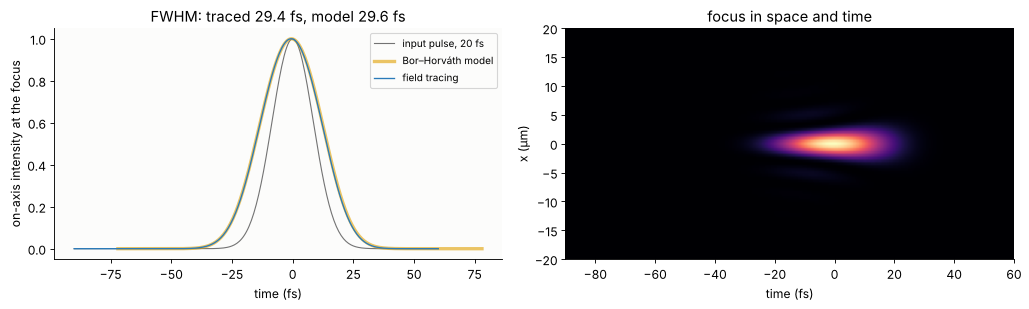

In [9]:
t = np.linspace(-90, 60, 301)
Ef = res.intensity("focus", t, np.array([0.0]), np.array([0.0]))[:, 0]
I_xt = res.intensity("focus", t, xf, np.zeros_like(xf))

om, o0 = pulse.omegas, pulse.omega0
spec = np.exp(-((om - o0)*20.0)**2/(8*np.log(2)))
E_bor = uf.to_time(uf.bor_axis_spectrum(om, spec, delay, dgdd=rays.gdd[1] - rays.gdd[0],
                                         omega0=o0), om, t, o0)
I_bor = np.abs(E_bor)**2
I_in = np.exp(-4*np.log(2)*t**2/20.0**2)
shift = t[np.argmax(Ef)] - t[np.argmax(I_bor)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t, I_in, color=GREY, lw=1, label="input pulse, 20 fs")
ax[0].plot(t + shift, I_bor/I_bor.max(), color=ORANGE, lw=3, alpha=0.6, label="Bor–Horváth model")
ax[0].plot(t, Ef/Ef.max(), color=BLUE, lw=1.2, label="field tracing")
ax[0].set_xlabel("time (fs)"); ax[0].set_ylabel("on-axis intensity at the focus")
ax[0].legend(fontsize=9)
ax[0].set_title("FWHM: traced {:.1f} fs, model {:.1f} fs".format(uf.fwhm(t, Ef), uf.fwhm(t, I_bor)))
im = ax[1].imshow(I_xt.T/I_xt.max(), extent=[t[0], t[-1], 1e3*xf[0], 1e3*xf[-1]], aspect="auto",
                  origin="lower", cmap="magma")
ax[1].set_xlabel("time (fs)"); ax[1].set_ylabel("x (µm)"); ax[1].set_title("focus in space and time")
plt.tight_layout(); plt.show()

The traced focal pulse is half again as long as the input pulse and has
the flat top and the slope of the model, although the chain knows nothing
about Bor's delay: it only traces 24 monochromatic fields, each through
the lens at its own index, and adds them coherently in the focus. The
model is a ray picture of the same physics and agrees with it
(the time axis of the model is shifted onto the traced pulse; field tracing
measures time from the group delay of the focal field). In space and time
(right) the focus is a short, fat blob: the pulse front at the edge of the
beam arrives first and is focused into the wide wings of the spot, the
late light from the centre of the lens builds the axial peak. An achromat
($dP/d\lambda = 0$) would remove the delay.

## Summary

- A partially coherent, polychromatic or pulsed source is a set of
  harmonic **modes**; a field tracing chain traces each one, and the
  detector adds them incoherently (irradiance, mutual intensity) or
  coherently (the spectral fields of a pulse).
- The **Gaussian Schell model** decomposes into Hermite–Gaussian modes with
  geometrically falling weights; it spreads like a Gaussian beam with an
  $M^2$-fold shorter Rayleigh length and keeps its coherence width
  in proportion to its width.
- A **thermal multimode laser** is the same model; only the power of the
  embedded fundamental mode couples into a matched single-mode fibre.
- An **extended source** is an incoherent ensemble of point emitters; the
  van Cittert–Zernike theorem follows, with or without a collimator.
- **Spectra** wash out interference beyond the coherence length; the
  coherent spectral fields of a **pulse** through a dispersive lens give
  the space-time focus, including Bor's pulse-front delay.

References: F. Wyrowski and M. Kuhn, J. Mod. Opt. 58, 449 (2011);
F. Gori, Opt. Commun. 46, 149 (1983); A. Starikov and E. Wolf, JOSA 72,
923 (1982); L. Mandel and E. Wolf, *Optical coherence and quantum optics*
(1995); Z. Bor, J. Mod. Opt. 35, 1907 (1988).

In [10]:
print("total run time: {:.0f} s".format(time.time() - t_start))

total run time: 24 s
